# CardioIA · Preparação das radiografias
O ChestMNIST 64 distribui radiografias NIH já reduzidas de 1024 × 1024 para 64 × 64. Usamos a coluna 1 (cardiomegalia) e mantemos as partições da fonte. O exercício simula a análise de exames usando dados públicos. O teste atual exclui os índices já avaliados na versão inicial e as suas cópias exatas.

In [1]:
from pathlib import Path
import subprocess
import sys

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fase4/src").is_dir()), None)
if raiz is None:
    raiz = Path.cwd() / "cardioia-fase4-revisao"
    if not (raiz / "fase4/src").is_dir():
        subprocess.run(["git", "clone", "--branch", "fase4", "--depth", "1",
                        "https://github.com/marcus-vlgarcia/cardioia.git", str(raiz)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(raiz / "fase4/requirements.txt")], check=True)
sys.path.insert(0, str(raiz / "fase4/src"))


In [2]:
import pandas as pd
from dados import baixar, carregar_particoes, preparar_imagem

arquivo = baixar()
datasets = carregar_particoes(arquivo)
pd.DataFrame([
    {"Partição": split, "Exames oficiais": ds.total_oficial, "Exames usados": len(ds),
     "Com rótulo": int(ds.rotulos.sum()), "Sem rótulo": len(ds) - int(ds.rotulos.sum())}
    for split, ds in datasets.items()
])

,Partição,Exames oficiais,Exames usados,Com rótulo,Sem rótulo
0,train,78468,9750,1950,7800
1,val,11219,7997,179,7818
2,test,22433,14432,392,14040


## Conversão e normalização
O arquivo NPZ fornece matrizes uint8 em escala de cinza. Cada imagem é convertida para RGB, redimensionada para 56 × 56 e convertida em tensor float32 no intervalo [0, 1]. Para entradas de tamanho diferente, o redimensionamento preserva a proporção com bordas. A ResNet18 recebe, adicionalmente, a normalização por canal do ImageNet.

In [3]:
import inspect
print(inspect.getsource(preparar_imagem))
print(inspect.getsource(carregar_particoes))

def preparar_imagem(imagem):
    """Converte para RGB e redimensiona proporcionalmente com fundo preto."""
    imagem = imagem.convert("RGB")
    if imagem.size != (TAMANHO, TAMANHO):
        escala = TAMANHO / max(imagem.size)
        imagem = imagem.resize(tuple(max(1, round(lado * escala)) for lado in imagem.size),
                               Image.Resampling.BILINEAR)
    tela = Image.new("RGB", (TAMANHO, TAMANHO))
    tela.paste(imagem, tuple((TAMANHO - lado) // 2 for lado in imagem.size))
    return torch.from_numpy(np.array(tela)).permute(2, 0, 1).float() / 255

def carregar_particoes(arquivo):
    datasets = {split: Radiografias(arquivo, split) for split in PARTICOES}
    vistos = set()
    for ds in datasets.values():
        vistos.update(ds.hashes_teste_anterior)
        manter = np.zeros(len(ds), dtype=bool)
        for i, img in enumerate(ds.imagens):
            chave = hash_imagem(img)
            if chave not in vistos:
                manter[i] = True
              

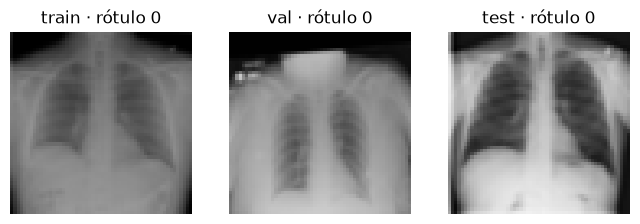

In [4]:
import matplotlib.pyplot as plt
fig, eixos = plt.subplots(1, 3, figsize=(8, 3))
for eixo, (split, ds) in zip(eixos, datasets.items()):
    x, rotulo = ds[0]
    assert x.shape == (3, 56, 56) and 0 <= x.min() <= x.max() <= 1
    eixo.imshow(x.permute(1, 2, 0))
    eixo.set_title(f"{split} · rótulo {rotulo}")
    eixo.axis("off")
plt.show()